In [4]:
import xarray as xr
from windspharm.xarray import VectorWind

In [5]:
p = "/glade/derecho/scratch/adixit/India_Heatwave/DATA/era5_data/"

periods = {
    "25 May - 1 Jun": slice("2024-05-25", "2024-06-01"),
    "10 - 20 Jun": slice("2024-06-10", "2024-06-20")
}
boxes = {L: dict(latitude=slice(30, 22), longitude=slice(75, 85)) for L in [500, 850]}

half, kappa = 250, 287.05 / 1004.

In [7]:
t_ds = xr.open_dataset(p + "T/t.2024.era5.nc")
u_ds = xr.open_dataset(p + "U/u.2024.era5.nc")
v_ds = xr.open_dataset(p + "V/v.2024.era5.nc")
w_ds = xr.open_dataset(p + "W/w.2024.era5.nc")

In [8]:
def budget_at(time, L, box):
    # Global fields at target pressure level
    sel = dict(time=time, level=L)
    T = t_ds["T"].sel(**sel).compute()
    U = u_ds["U"].sel(**sel).compute()
    V = v_ds["V"].sel(**sel).compute()

    # Spherical harmonic horizontal derivatives
    wind = VectorWind(U, V, legfunc="computed")
    Tx, Ty = wind.gradient(T)

    hadv = (-(U * Tx + V * Ty) * 86400).sel(**box)  # K/day
    D = wind.divergence().sel(**box)                 # s^-1

    # Regional fields for vertical derivatives
    sel3 = dict(time=time, level=slice(L-half, L+half), **box)
    T3 = t_ds["T"].sel(**sel3).compute()
    W3 = w_ds["W"].sel(**sel3).compute()

    T0, W0 = T3.sel(level=L), W3.sel(level=L)

    # Temperature budget (K/day)
    tend = T0.differentiate("time", datetime_unit="D")
    vadv = -W0 * T3.differentiate("level").sel(level=L) * 864
    adiab = W0 * kappa * T0 / (L * 100) * 86400
    diab = tend - hadv - vadv - adiab

    # Mass divergence (day^-1)
    dwdp = W3.differentiate("level").sel(level=L) / 100
    hfd = D * 86400
    vfd = dwdp * 86400
    tfd = hfd + vfd
    cres = D + dwdp

    # Negative divergence of total temperature flux (K/day)
    flux_adv = hadv + vadv - T0 * tfd

    def bm(x):
        return float(x.mean())

    budget = {
        "Temperature\ntendency": bm(tend),
        "Horizontal\nadvection": bm(hadv),
        "Vertical\nadvection": bm(vadv),
        "Adiabatic\nheating": bm(adiab),
        "Diabatic\n(residual)": bm(diab)
    }

    flux = {
        "Horizontal\ndivergence": bm(hfd),
        "Vertical\ndivergence": bm(vfd),
        "Total\ndivergence": bm(tfd)
    }

    diag = {
        "omega (hPa/day, +=descent)": bm(W0) * 864,
        "net vertical (K/day)": bm(vadv + adiab),
        "-(flux div) (K/day)": bm(flux_adv),
        "hadv+vadv (K/day)": bm(hadv + vadv),
        "continuity resid (1e-6/s)": bm(cres) * 1e6,
        "T*resid (K/day)": bm(T0 * cres) * 86400
    }

    return budget, flux, diag


In [9]:
results = {}
for L, box in boxes.items():
    results[L] = {name: budget_at(tsl, L, box) for name, tsl in periods.items()}
    print(f"\n=== {L} hPa, box {box['latitude'].start}-{box['latitude'].stop}N, "
          f"{box['longitude'].start}-{box['longitude'].stop}E ===")
    for name, (b, f, d) in results[L].items():
        print(name)
        for k, x in d.items():
            print(f"   {k:30s} {x:8.2f}")


=== 500 hPa, box 30-22N, 75-85E ===
25 May - 1 Jun
   omega (hPa/day, +=descent)        24.63
   net vertical (K/day)               1.79
   -(flux div) (K/day)              -13.65
   hadv+vadv (K/day)                 -3.46
   continuity resid (1e-6/s)          0.44
   T*resid (K/day)                   10.20
10 - 20 Jun
   omega (hPa/day, +=descent)         9.00
   net vertical (K/day)               0.43
   -(flux div) (K/day)               -8.32
   hadv+vadv (K/day)                 -2.29
   continuity resid (1e-6/s)          0.26
   T*resid (K/day)                    6.03

=== 850 hPa, box 30-22N, 75-85E ===
25 May - 1 Jun
   omega (hPa/day, +=descent)       -59.46
   net vertical (K/day)              -0.99
   -(flux div) (K/day)               -9.72
   hadv+vadv (K/day)                  4.62
   continuity resid (1e-6/s)          0.57
   T*resid (K/day)                   14.34
10 - 20 Jun
   omega (hPa/day, +=descent)       -60.57
   net vertical (K/day)              -1.49
   -(flux di

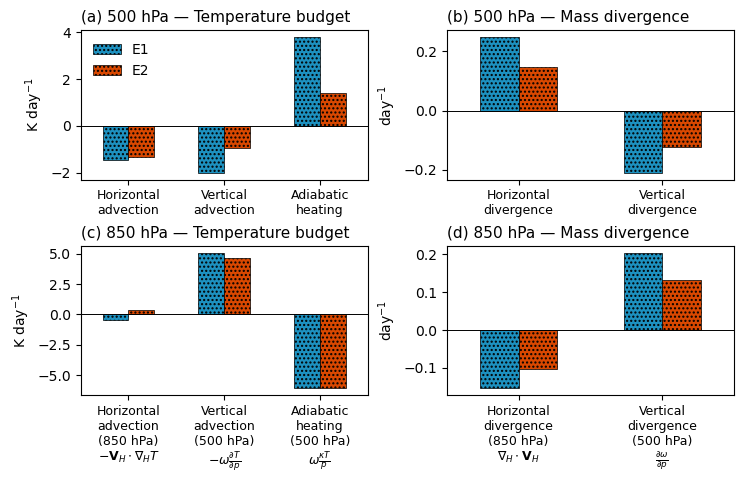

In [23]:
colors = ['#1d91c0', '#d94801']
periods = list(results[500])
bw, step = 0.25, 0.93

xtk1 = [
    'Horizontal\nadvection\n(850 hPa)\n' r'$-\mathbf{V}_H\cdot\nabla_H T$',
    'Vertical\nadvection\n(500 hPa)\n' r'$-\omega\frac{\partial T}{\partial p}$',
    'Adiabatic\nheating\n(500 hPa)\n' r'$\omega\frac{\kappa T}{p}$',
    #'Diabatic\nresidual\n(850 hPa)\n' r'$\partial T/\partial t-\mathrm{Dynamics}$',
    #'Horizontal\ndivergence\n(850 hPa)\n' r'$\nabla_H\cdot\mathbf{V}_H$',
    #'Vertical\ndivergence\n(500 hPa)\n' r'$\frac{\partial\omega}{\partial p}$'
]

xtk2 = [
    #'Horizontal\nadvection\n(850 hPa)\n' r'$-\mathbf{V}_H\cdot\nabla_H T$',
    #'Vertical\nadvection\n(500 hPa)\n' r'$-\omega\frac{\partial T}{\partial p}$',
    #'Adiabatic\nheating\n(500 hPa)\n' r'$\omega\frac{\kappa T}{p}$',
    #'Diabatic\nresidual\n(850 hPa)\n' r'$\partial T/\partial t-\mathrm{Dynamics}$',
    'Horizontal\ndivergence\n(850 hPa)\n' r'$\nabla_H\cdot\mathbf{V}_H$',
    'Vertical\ndivergence\n(500 hPa)\n' r'$\frac{\partial\omega}{\partial p}$'
]


items = [
    (0, ['Horizontal\nadvection', 'Vertical\nadvection',
         'Adiabatic\nheating', ],
        ['Horizontal\nadvection', 'Vertical\nadvection',
         'Adiabatic\nheating', ]),
    (1, ['Horizontal\ndivergence', 'Vertical\ndivergence'],
        ['Horizontal\ndivergence', 'Vertical\ndivergence'])
]
mm = 1 / 25.4
fig, axs = plt.subplots(2, 2, figsize=(186 * mm, 120 * mm),constrained_layout=True)

for i, L in enumerate([500, 850]):
    for j, (idx, keys, labels) in enumerate(items):
        ax = axs[i, j]
        x = np.arange(len(keys)) * step

        for k, period in enumerate(periods):
            vals = [results[L][period][idx][key] for key in keys]
            ax.bar(x+(k-.5)*bw, vals, bw, label=['E1','E2'][k],
                   color=colors[k], hatch='....', edgecolor='k', lw=.5)

        ax.set_xticks(x, labels, fontsize=9)
        ax.set_xlim(-step/2, x[-1]+step/2)
        ax.axhline(0, color='k', lw=.7)
        ax.set_ylabel('K day$^{-1}$' if j==0 else 'day$^{-1}$')
        ax.set_title(f"({chr(97+i*2+j)}) {L} hPa — "
                     f"{'Temperature budget' if j==0 else 'Mass divergence'}",
                     loc='left', fontsize=11)
        #ax.set_xticks(x, [label for _, _, _, label in items[i]], fontsize=10)
        if i==1:
            if j==0:
                ax.set_xticklabels(xtk1)
            else:
                ax.set_xticklabels(xtk2)
        

axs[0,0].legend(frameon=False)
plt.savefig('heatBudget.pdf', dpi=300, format='pdf', transparent=True)